<a href="https://colab.research.google.com/github/XuningZhuang/MSSP6070/blob/main/WeeklyModules/Week11/Week_11_Exercise_Xuning_Zhuang_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import userdata
import os

github_token = userdata.get('6070777')
owner = 'XuningZhuang'
repository = 'MSSP6070'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

!rm -rf {repository}

!git clone {clone_url}


Cloning into 'MSSP6070'...
remote: Enumerating objects: 261, done.
remote: Counting objects: 100% (52/52), done.
remote: Compressing objects: 100% (46/46), done.
remote: Total 261 (delta 23), reused 23 (delta 6), pack-reused 209 (from 1)
Receiving objects: 100% (261/261), 18.43 MiB | 13.45 MiB/s, done.
Resolving deltas: 100% (137/137), done.


In [3]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/MSSP6070/data/CA_Legislative_Districts.csv', encoding='latin-1')

In [4]:
geo_path = '/content/MSSP6070/data/california-congressional-districts.geojson'
# geojson is a format suitable for processing geographic files. 处理地理文件的格式
districts = gpd.read_file(geo_path)

print(districts.head())

  Name description descriptio  \
0   01        None              
1   02        None              
2   03        None              
3   04        None              
4   05        None              

                                            geometry  
0  MULTIPOLYGON (((-120.07192 41.99495, -120.0010...  
1  MULTIPOLYGON (((-123.69821 41.81719, -123.6967...  
2  MULTIPOLYGON (((-121.667 39.30511, -121.63015 ...  
3  MULTIPOLYGON (((-120.37731 37.61679, -120.3823...  
4  MULTIPOLYGON (((-122.16384 38.64288, -122.1659...  


In [5]:
districts['DISTRICT'] = districts['Name'].astype(int)
#notes for myself：在geojson（districts）数据中，选区编号存储在 Name 列，内容为字符串型（如 '01', '02'）。而 CSV 数据（df）当中的选区编号 DISTRICT 是整数型（例如 1, 2）。
#所以为了能够成功把两张表关联起来，这行代码将 districts['Name'] 转换为整数型（int），并把结果存入新创建的 DISTRICT 列，从而确保两张表的关联键数据类型一致。

print('CSV districts:', df['DISTRICT'].nunique())
print('GeoJSON districts:', districts['DISTRICT'].nunique())

CSV districts: 52
GeoJSON districts: 53


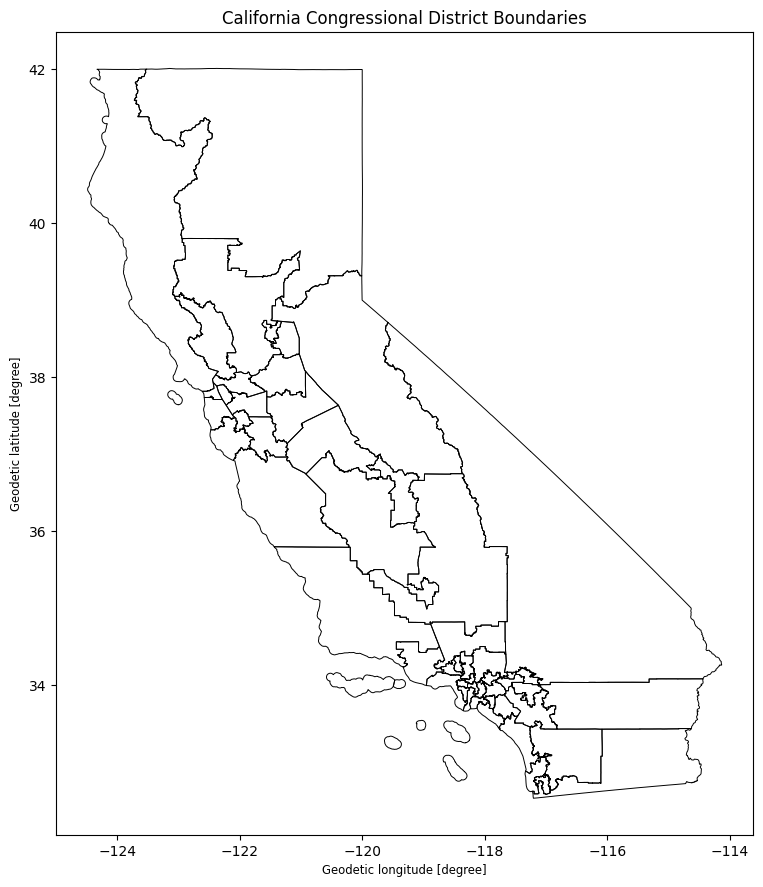

In [6]:
#1 Visualize California's Congressional Districts
fig, ax = plt.subplots(figsize=(9, 11))  #create画布和子图坐标轴

districts.boundary.plot(ax=ax, color='black', linewidth=0.7)

ax.set_title('California Congressional District Boundaries')
ax.set_axis_on()

plt.show()

In [8]:
#2 Overlay the Population om the congressional districts
ca_map = districts.merge(df[['DISTRICT', 'POPULATION', 'CVAP_19']], on='DISTRICT', how='left')     #on='DISTRICRT'的意思就是指定使用两张表共有的 DISTRICT（选区编号）列作为关联键进行匹配连接。 左连接（Left Join） 方式。这意味着保留 districts（地图数据）中的所有选区，如果在 df（人口数据）中找不到对应的选区，则对应的人口字段会填为 NaN（空值）

print(ca_map[['DISTRICT', 'POPULATION', 'CVAP_19']].head())

   DISTRICT  POPULATION   CVAP_19
0         1    760066.0  549203.0
1         2    760067.0  556808.0
2         3    760065.0  549415.0
3         4    760065.0  529902.0
4         5    760065.0  546620.0


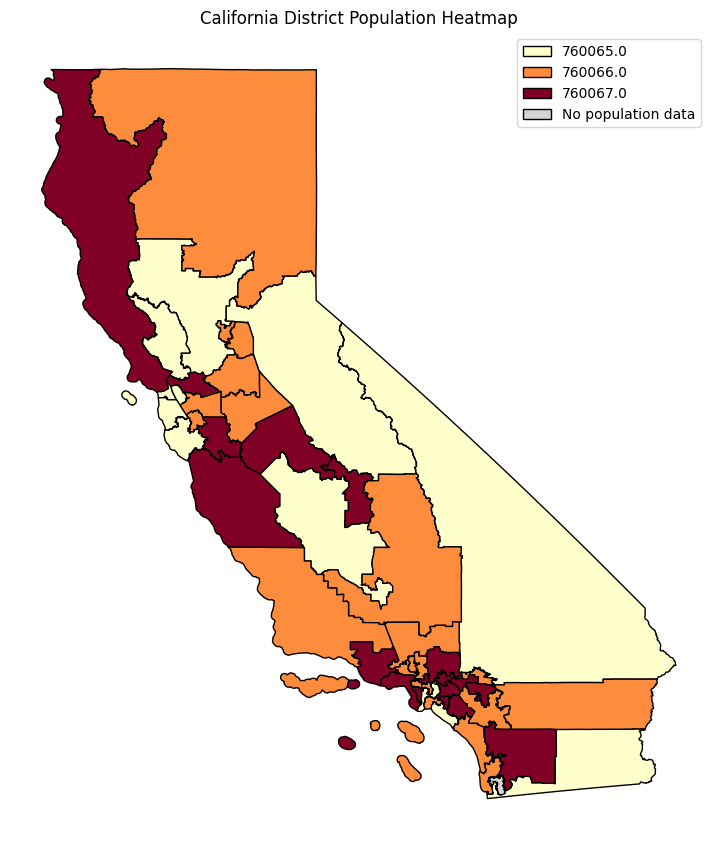

In [9]:
#3 a visualization of the California Congressional districts
fig, ax = plt.subplots(figsize=(9, 11))

ca_map.plot(
    column='POPULATION',     #因为是指定要可视化的数据列，所以是column
    categorical=True,
    cmap='YlOrRd',
    legend=True,
    edgecolor='black',
    missing_kwds={ 'color': 'lightgray',
                  'label': 'No population data'},
    ax=ax)


ax.set_title('California District Population Heatmap')
ax.set_axis_off()

plt.show()